In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
BASE_DIR = Path("..")

DATA_DIR = BASE_DIR / "data"
VISUALS_DIR = BASE_DIR / "visuals"

DATA_DIR.mkdir(exist_ok=True)
VISUALS_DIR.mkdir(exist_ok=True)

print("Folders ready!")

Folders ready!


In [3]:
# ============================================================
# HR ANALYTICS DATASET
# ============================================================

np.random.seed(42)

n = 1500

# -----------------------------
# Basic Information
# -----------------------------

employee_ids = [
    f"EMP{1000+i}"
    for i in range(n)
]

genders = [
    "Male",
    "Female"
]

departments = [
    "Sales",
    "Research & Development",
    "Human Resources",
    "Finance",
    "IT",
    "Marketing"
]

job_roles = [
    "Manager",
    "Senior Analyst",
    "Junior Analyst",
    "Sales Executive",
    "HR Executive",
    "Software Engineer",
    "Data Analyst",
    "Accountant",
    "Marketing Specialist"
]

education_levels = [
    "High School",
    "Bachelor",
    "Master",
    "PhD"
]

marital_status = [
    "Single",
    "Married",
    "Divorced"
]

overtime_options = [
    "Yes",
    "No"
]

travel_options = [
    "Rarely",
    "Frequently",
    "Never"
]

# -----------------------------
# Generate employee data
# -----------------------------

age = np.random.randint(
    20,
    61,
    n
)

gender = np.random.choice(
    genders,
    n
)

department = np.random.choice(
    departments,
    n
)

job_role = np.random.choice(
    job_roles,
    n
)

education = np.random.choice(
    education_levels,
    n,
    p=[0.15, 0.45, 0.30, 0.10]
)

marital = np.random.choice(
    marital_status,
    n,
    p=[0.35, 0.50, 0.15]
)

years_at_company = np.random.randint(
    0,
    21,
    n
)

total_working_years = np.maximum(
    years_at_company,
    np.random.randint(1, 25, n)
)

monthly_income = np.random.randint(
    25000,
    180000,
    n
)

job_satisfaction = np.random.randint(
    1,
    5,
    n
)

work_life_balance = np.random.randint(
    1,
    5,
    n
)

performance_rating = np.random.randint(
    1,
    5,
    n
)

job_involvement = np.random.randint(
    1,
    5,
    n
)

overtime = np.random.choice(
    overtime_options,
    n,
    p=[0.30, 0.70]
)

business_travel = np.random.choice(
    travel_options,
    n,
    p=[0.55, 0.30, 0.15]
)

training_times = np.random.randint(
    0,
    7,
    n
)

distance_from_home = np.random.randint(
    1,
    50,
    n
)

# -----------------------------
# Attrition Logic
# -----------------------------

attrition_probability = (
    0.08
    + (age < 30) * 0.08
    + (overtime == "Yes") * 0.15
    + (job_satisfaction == 1) * 0.12
    + (work_life_balance == 1) * 0.08
    + (years_at_company < 2) * 0.10
    + (monthly_income < 45000) * 0.08
)

attrition_probability = np.clip(
    attrition_probability,
    0.03,
    0.75
)

attrition = np.where(
    np.random.random(n) < attrition_probability,
    "Yes",
    "No"
)

# -----------------------------
# Create DataFrame
# -----------------------------

df = pd.DataFrame({

    "Employee_ID": employee_ids,

    "Age": age,

    "Gender": gender,

    "Department": department,

    "Job_Role": job_role,

    "Education": education,

    "Marital_Status": marital,

    "Years_At_Company": years_at_company,

    "Total_Working_Years": total_working_years,

    "Monthly_Income": monthly_income,

    "Job_Satisfaction": job_satisfaction,

    "Work_Life_Balance": work_life_balance,

    "Performance_Rating": performance_rating,

    "Job_Involvement": job_involvement,

    "Overtime": overtime,

    "Business_Travel": business_travel,

    "Training_Times": training_times,

    "Distance_From_Home": distance_from_home,

    "Attrition": attrition
})

# -----------------------------
# Display dataset
# -----------------------------

print("Dataset created successfully!")

print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)

df.head()

Dataset created successfully!
Rows: 1500
Columns: 19


,Employee_ID,Age,Gender,Department,Job_Role,Education,Marital_Status,Years_At_Company,Total_Working_Years,Monthly_Income,Job_Satisfaction,Work_Life_Balance,Performance_Rating,Job_Involvement,Overtime,Business_Travel,Training_Times,Distance_From_Home,Attrition
0,EMP1000,58,Female,Research & Development,Software Engineer,High School,Single,16,21,92143,2,1,2,3,No,Rarely,2,14,No
1,EMP1001,48,Female,Human Resources,Junior Analyst,PhD,Single,13,13,145623,2,3,2,2,Yes,Rarely,6,10,No
2,EMP1002,34,Female,Finance,Sales Executive,Master,Single,3,15,135013,1,1,2,3,No,Rarely,3,10,No
3,EMP1003,27,Female,Finance,Marketing Specialist,Bachelor,Married,16,22,27016,4,3,3,3,No,Rarely,5,18,No
4,EMP1004,40,Female,Human Resources,HR Executive,Master,Married,16,16,94110,4,2,2,2,Yes,Frequently,2,24,No


In [4]:
print("========== DATASET INFO ==========")

print(df.info())

print("\n========== FIRST 5 ROWS ==========")

display(df.head())

print("\n========== MISSING VALUES ==========")

print(df.isnull().sum())

print("\n========== DUPLICATES ==========")

print(df.duplicated().sum())

========== DATASET INFO ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Employee_ID          1500 non-null   object
 1   Age                  1500 non-null   int32 
 2   Gender               1500 non-null   object
 3   Department           1500 non-null   object
 4   Job_Role             1500 non-null   object
 5   Education            1500 non-null   object
 6   Marital_Status       1500 non-null   object
 7   Years_At_Company     1500 non-null   int32 
 8   Total_Working_Years  1500 non-null   int32 
 9   Monthly_Income       1500 non-null   int32 
 10  Job_Satisfaction     1500 non-null   int32 
 11  Work_Life_Balance    1500 non-null   int32 
 12  Performance_Rating   1500 non-null   int32 
 13  Job_Involvement      1500 non-null   int32 
 14  Overtime             1500 non-null   object
 15  Business_Travel     

,Employee_ID,Age,Gender,Department,Job_Role,Education,Marital_Status,Years_At_Company,Total_Working_Years,Monthly_Income,Job_Satisfaction,Work_Life_Balance,Performance_Rating,Job_Involvement,Overtime,Business_Travel,Training_Times,Distance_From_Home,Attrition
0,EMP1000,58,Female,Research & Development,Software Engineer,High School,Single,16,21,92143,2,1,2,3,No,Rarely,2,14,No
1,EMP1001,48,Female,Human Resources,Junior Analyst,PhD,Single,13,13,145623,2,3,2,2,Yes,Rarely,6,10,No
2,EMP1002,34,Female,Finance,Sales Executive,Master,Single,3,15,135013,1,1,2,3,No,Rarely,3,10,No
3,EMP1003,27,Female,Finance,Marketing Specialist,Bachelor,Married,16,22,27016,4,3,3,3,No,Rarely,5,18,No
4,EMP1004,40,Female,Human Resources,HR Executive,Master,Married,16,16,94110,4,2,2,2,Yes,Frequently,2,24,No



========== MISSING VALUES ==========
Employee_ID            0
Age                    0
Gender                 0
Department             0
Job_Role               0
Education              0
Marital_Status         0
Years_At_Company       0
Total_Working_Years    0
Monthly_Income         0
Job_Satisfaction       0
Work_Life_Balance      0
Performance_Rating     0
Job_Involvement        0
Overtime               0
Business_Travel        0
Training_Times         0
Distance_From_Home     0
Attrition              0
dtype: int64

========== DUPLICATES ==========
0


In [5]:
csv_path = DATA_DIR / "hr_employee_data.csv"

df.to_csv(
    csv_path,
    index=False
)

print("Dataset saved successfully!")
print(csv_path)

Dataset saved successfully!
..\data\hr_employee_data.csv


In [6]:
total_employees = len(df)

total_attrition = (
    df["Attrition"] == "Yes"
).sum()

attrition_rate = (
    total_attrition / total_employees
) * 100

average_age = df["Age"].mean()

average_income = df["Monthly_Income"].mean()

average_experience = df["Years_At_Company"].mean()

print("=" * 50)
print("HR ANALYTICS KPIs")
print("=" * 50)

print(f"Total Employees      : {total_employees}")
print(f"Employees Left       : {total_attrition}")
print(f"Attrition Rate       : {attrition_rate:.2f}%")
print(f"Average Age          : {average_age:.2f}")
print(f"Average Monthly Income: ₹{average_income:,.2f}")
print(f"Average Experience   : {average_experience:.2f} years")

print("=" * 50)

HR ANALYTICS KPIs
Total Employees      : 1500
Employees Left       : 321
Attrition Rate       : 21.40%
Average Age          : 40.53
Average Monthly Income: ₹102,790.77
Average Experience   : 10.06 years


HR ANALYTICS PROJECT

Dataset created successfully!
Rows    : 1500
Columns : 19

========== FIRST 5 ROWS ==========


,Employee_ID,Age,Gender,Department,Job_Role,Education,Marital_Status,Years_At_Company,Total_Working_Years,Monthly_Income,Job_Satisfaction,Work_Life_Balance,Performance_Rating,Job_Involvement,Overtime,Business_Travel,Training_Times,Distance_From_Home,Attrition
0,EMP1000,58,Female,Research & Development,Software Engineer,High School,Single,16,21,92143,2,1,2,3,No,Rarely,2,14,No
1,EMP1001,48,Female,Human Resources,Junior Analyst,PhD,Single,13,13,145623,2,3,2,2,Yes,Rarely,6,10,No
2,EMP1002,34,Female,Finance,Sales Executive,Master,Single,3,15,135013,1,1,2,3,No,Rarely,3,10,No
3,EMP1003,27,Female,Finance,Marketing Specialist,Bachelor,Married,16,22,27016,4,3,3,3,No,Rarely,5,18,No
4,EMP1004,40,Female,Human Resources,HR Executive,Master,Married,16,16,94110,4,2,2,2,Yes,Frequently,2,24,No



========== DATA TYPES ==========
Employee_ID            object
Age                     int32
Gender                 object
Department             object
Job_Role               object
Education              object
Marital_Status         object
Years_At_Company        int32
Total_Working_Years     int32
Monthly_Income          int32
Job_Satisfaction        int32
Work_Life_Balance       int32
Performance_Rating      int32
Job_Involvement         int32
Overtime               object
Business_Travel        object
Training_Times          int32
Distance_From_Home      int32
Attrition              object
dtype: object

========== MISSING VALUES ==========
Employee_ID            0
Age                    0
Gender                 0
Department             0
Job_Role               0
Education              0
Marital_Status         0
Years_At_Company       0
Total_Working_Years    0
Monthly_Income         0
Job_Satisfaction       0
Work_Life_Balance      0
Performance_Rating     0
Job_Involvement    

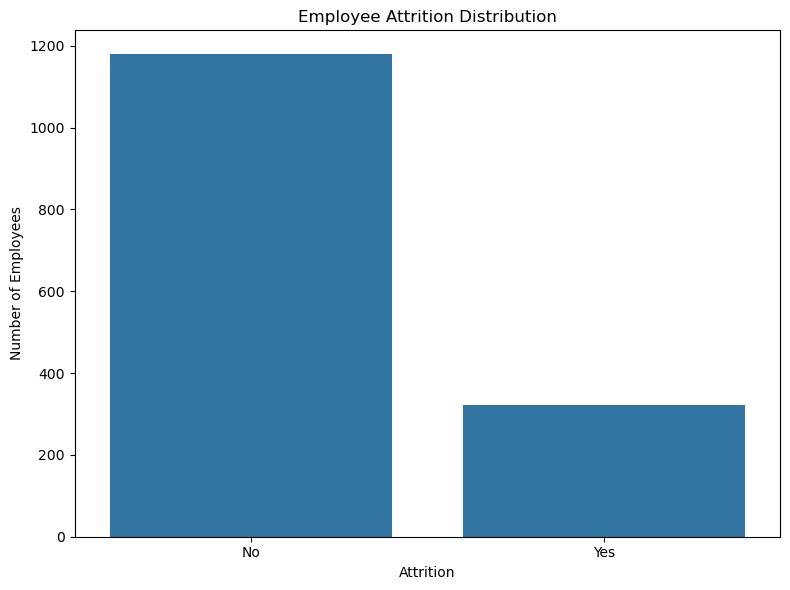


========== ATTRITION BY DEPARTMENT ==========
Attrition                No  Yes
Department                      
Finance                 201   71
Human Resources         207   49
IT                      207   49
Marketing               187   53
Research & Development  179   41
Sales                   198   58


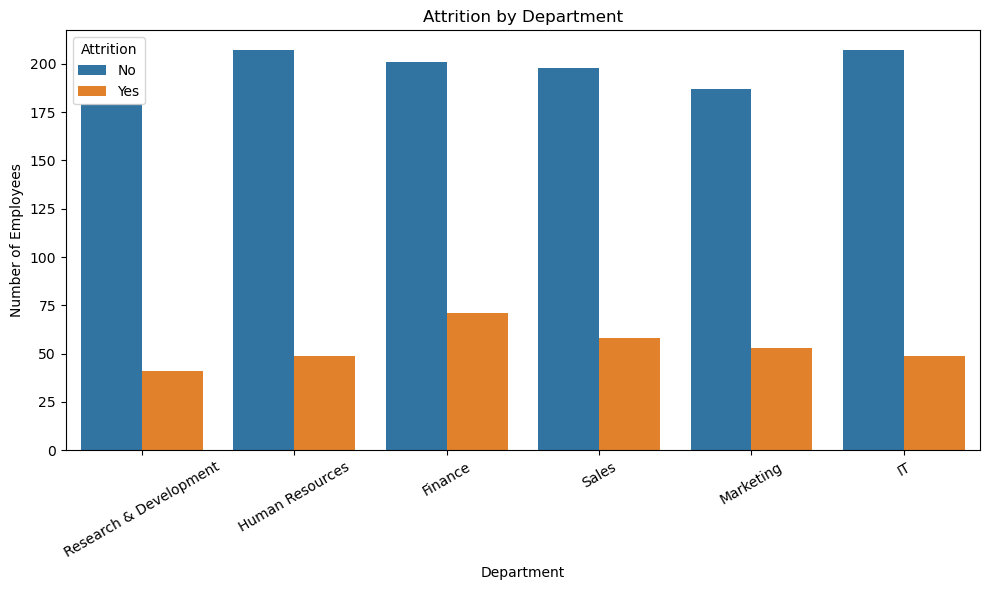

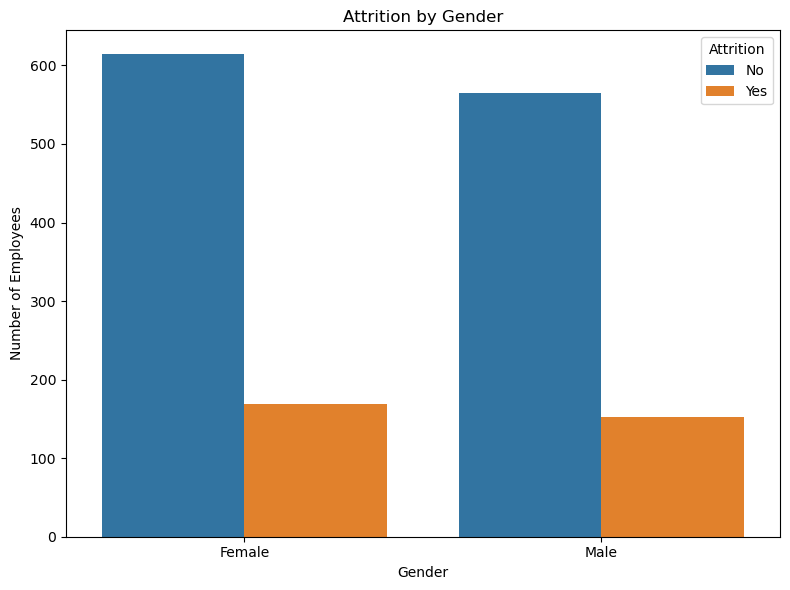


========== ATTRITION BY AGE GROUP ==========
Attrition   No  Yes
Age_Group          
20-29      268   88
30-39      263   63
40-49      308   84
50-60      340   86


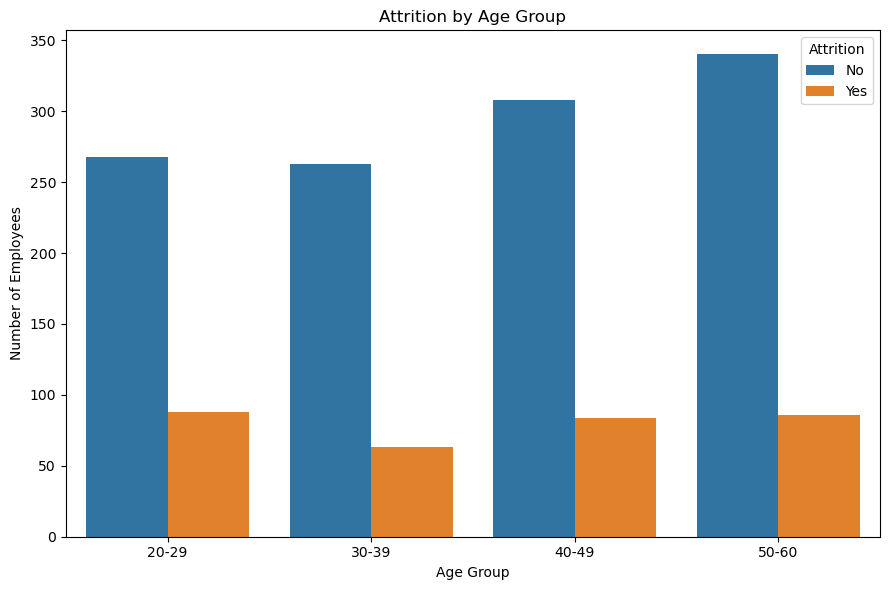

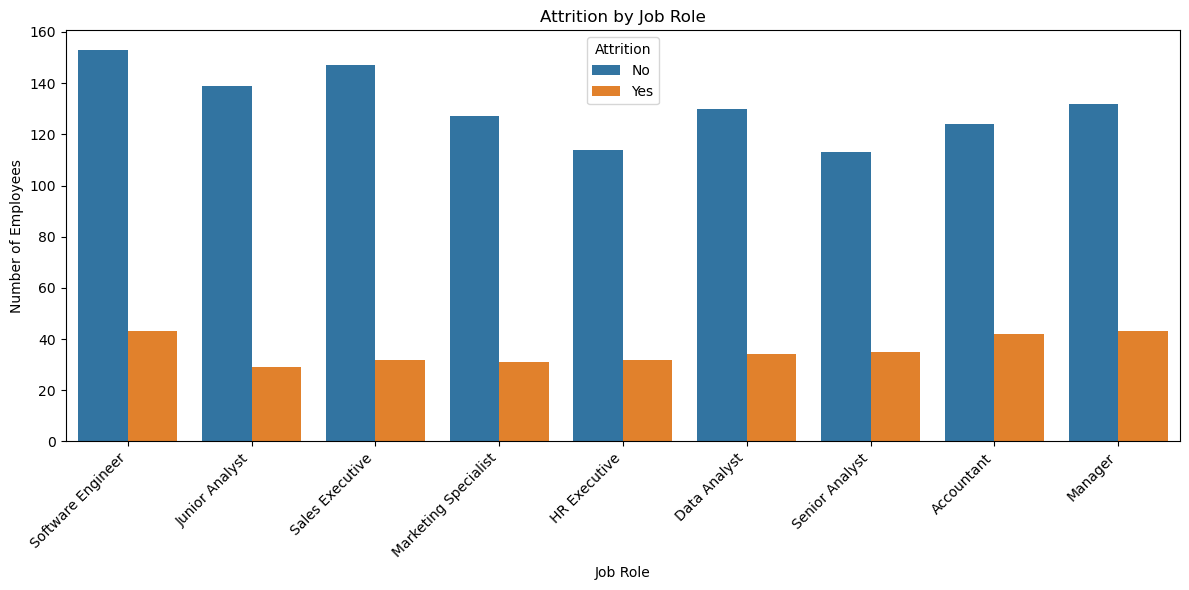

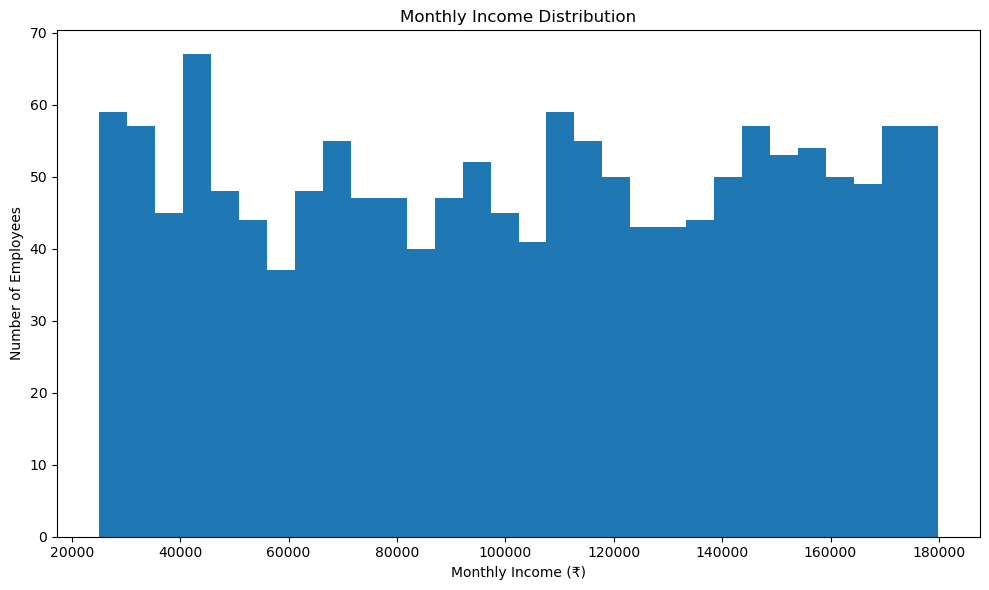


========== OVERTIME VS ATTRITION ==========
Attrition   No  Yes
Overtime           
No         870  175
Yes        309  146


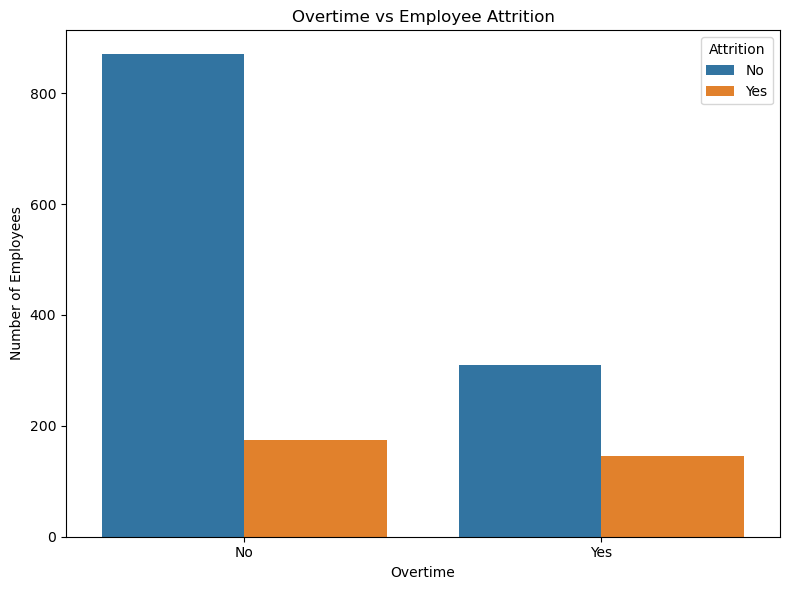


========== JOB SATISFACTION VS ATTRITION ==========
Attrition          No  Yes
Job_Satisfaction          
1                 243  119
2                 322   64
3                 307   75
4                 307   63


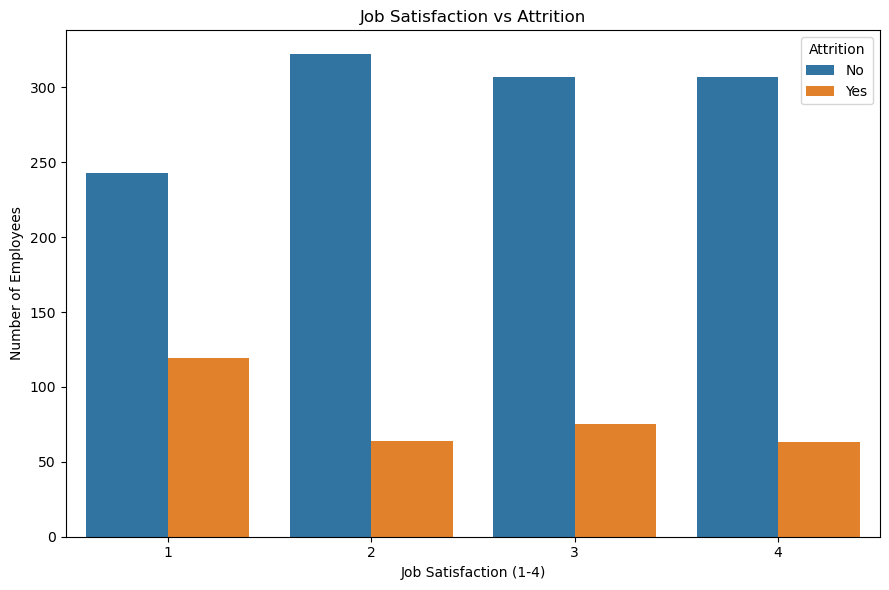

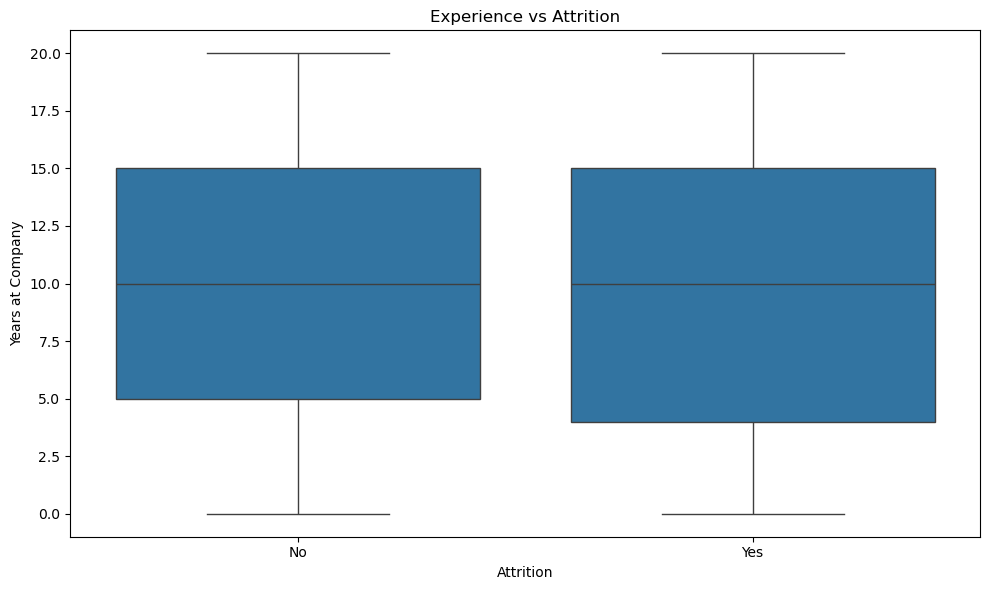

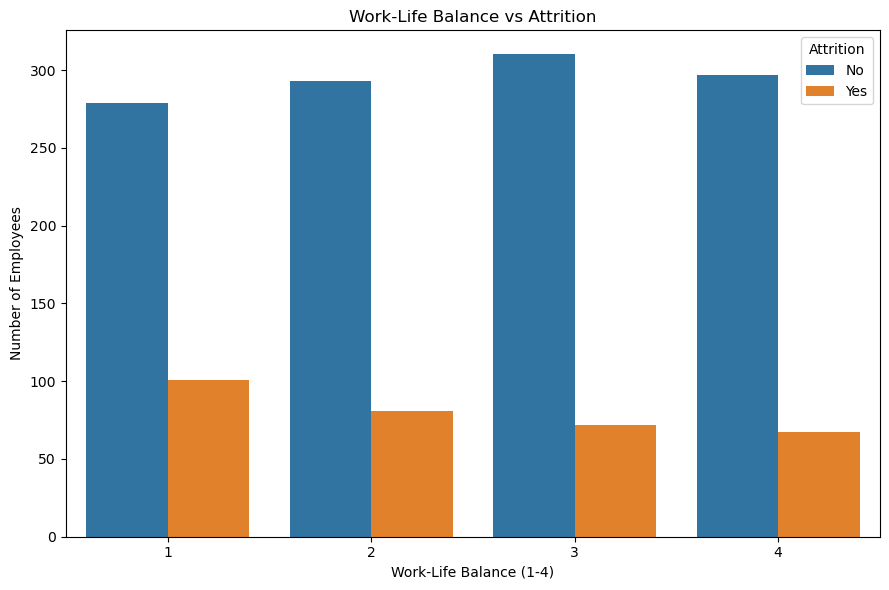


========== AVERAGE SALARY BY DEPARTMENT ==========
Department
Marketing                 106576.875000
Research & Development    105691.209091
Human Resources           103900.558594
IT                        103143.976562
Sales                      99728.992188
Finance                    98608.875000
Name: Monthly_Income, dtype: float64


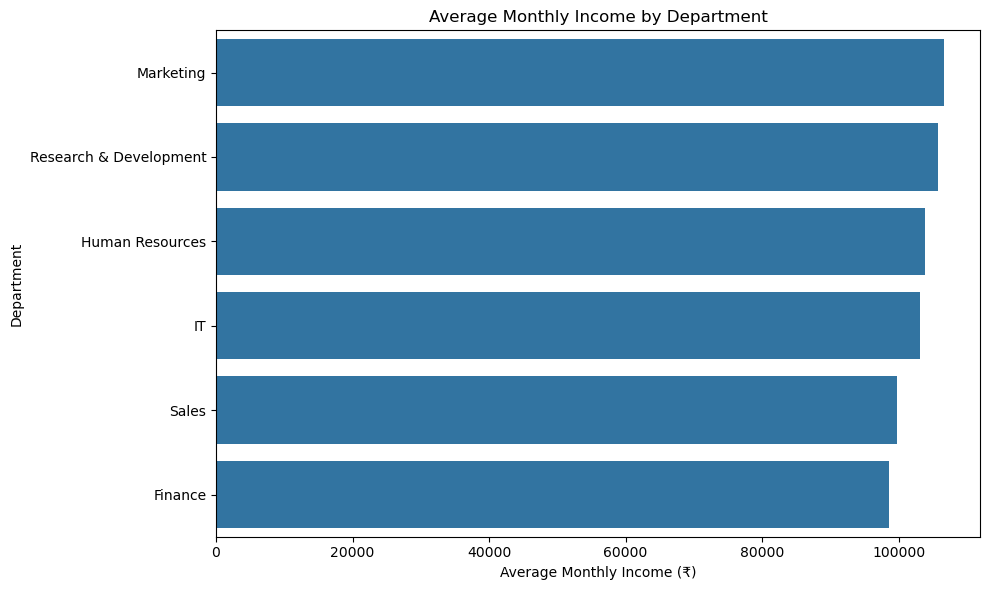


========== PERFORMANCE BY DEPARTMENT ==========
Department
Human Resources           2.597656
Finance                   2.533088
Research & Development    2.531818
Sales                     2.511719
IT                        2.425781
Marketing                 2.391667
Name: Performance_Rating, dtype: float64


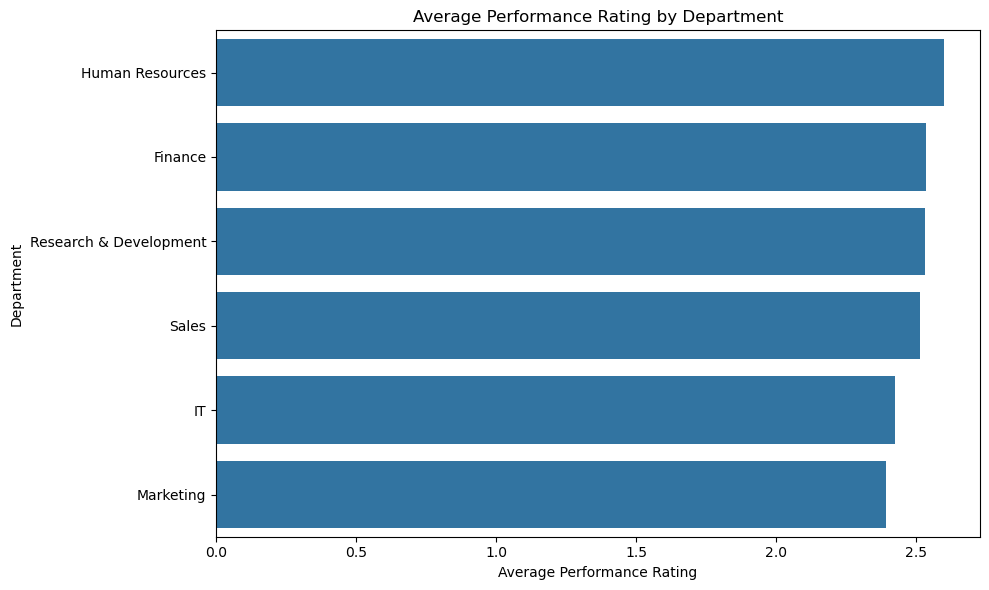


========== AVERAGE SALARY BY JOB ROLE ==========
Job_Role
Accountant              109237.379518
Manager                 106986.228571
Marketing Specialist    105066.898734
Software Engineer       101932.025510
Senior Analyst          101920.006757
Sales Executive         101331.117318
Data Analyst            100759.213415
HR Executive             99247.808219
Junior Analyst           98296.363095
Name: Monthly_Income, dtype: float64


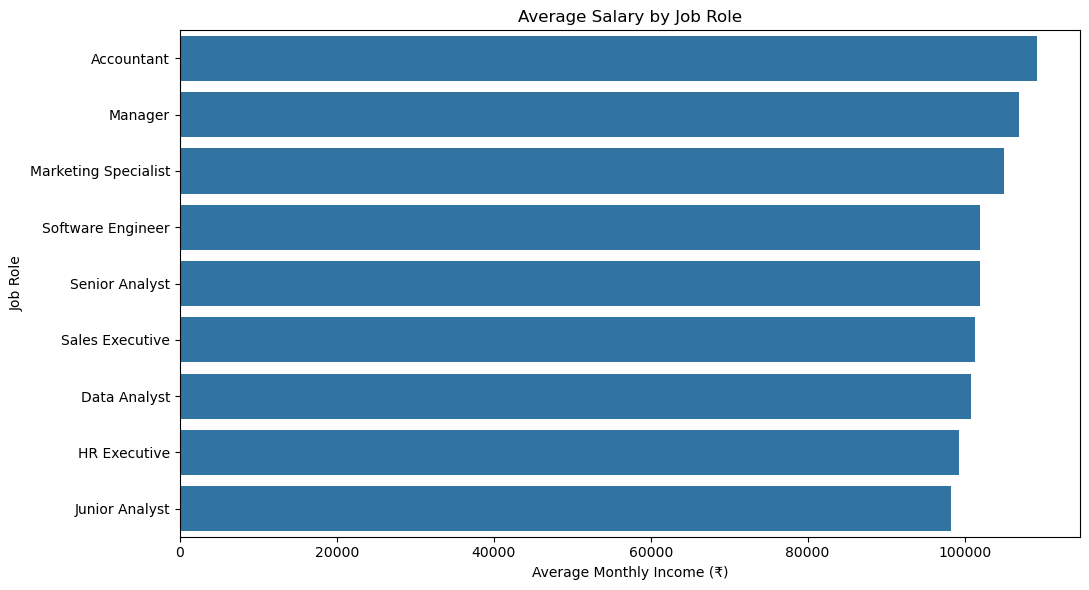

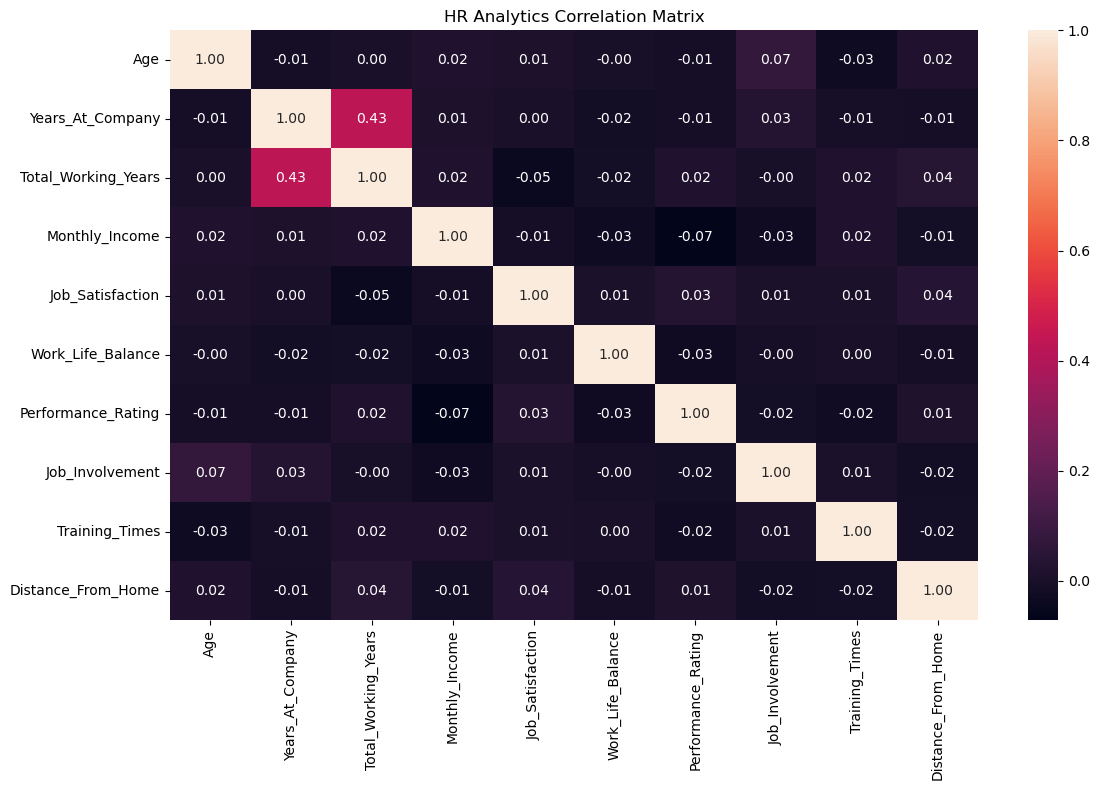



KEY BUSINESS INSIGHTS
1. Overall attrition rate: 21.40%
2. Department with highest attrition: Finance
3. Highest department attrition rate: 26.10%
4. Attrition among overtime employees: 32.09%
5. Attrition among non-overtime employees: 16.75%
6. Highest average salary department: Marketing
7. Highest average salary: ₹106,576.88

Dataset saved:
..\data\hr_employee_data.csv

Visualizations saved in:
..\visuals



In [11]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path



BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data"
VISUALS_DIR = BASE_DIR / "visuals"

DATA_DIR.mkdir(exist_ok=True)
VISUALS_DIR.mkdir(exist_ok=True)



np.random.seed(42)

n = 1500

employee_ids = [
    f"EMP{1000+i}" for i in range(n)
]

genders = ["Male", "Female"]

departments = [
    "Sales",
    "Research & Development",
    "Human Resources",
    "Finance",
    "IT",
    "Marketing"
]

job_roles = [
    "Manager",
    "Senior Analyst",
    "Junior Analyst",
    "Sales Executive",
    "HR Executive",
    "Software Engineer",
    "Data Analyst",
    "Accountant",
    "Marketing Specialist"
]

education_levels = [
    "High School",
    "Bachelor",
    "Master",
    "PhD"
]

marital_status = [
    "Single",
    "Married",
    "Divorced"
]



age = np.random.randint(20, 61, n)

gender = np.random.choice(
    genders,
    n
)

department = np.random.choice(
    departments,
    n
)

job_role = np.random.choice(
    job_roles,
    n
)

education = np.random.choice(
    education_levels,
    n,
    p=[0.15, 0.45, 0.30, 0.10]
)

marital = np.random.choice(
    marital_status,
    n,
    p=[0.35, 0.50, 0.15]
)

years_at_company = np.random.randint(
    0,
    21,
    n
)

total_working_years = np.maximum(
    years_at_company,
    np.random.randint(1, 25, n)
)

monthly_income = np.random.randint(
    25000,
    180000,
    n
)

job_satisfaction = np.random.randint(
    1,
    5,
    n
)

work_life_balance = np.random.randint(
    1,
    5,
    n
)

performance_rating = np.random.randint(
    1,
    5,
    n
)

job_involvement = np.random.randint(
    1,
    5,
    n
)

overtime = np.random.choice(
    ["Yes", "No"],
    n,
    p=[0.30, 0.70]
)

business_travel = np.random.choice(
    ["Rarely", "Frequently", "Never"],
    n,
    p=[0.55, 0.30, 0.15]
)

training_times = np.random.randint(
    0,
    7,
    n
)

distance_from_home = np.random.randint(
    1,
    50,
    n
)



attrition_probability = (
    0.08
    + (age < 30) * 0.08
    + (overtime == "Yes") * 0.15
    + (job_satisfaction == 1) * 0.12
    + (work_life_balance == 1) * 0.08
    + (years_at_company < 2) * 0.10
    + (monthly_income < 45000) * 0.08
)

attrition_probability = np.clip(
    attrition_probability,
    0.03,
    0.75
)

attrition = np.where(
    np.random.random(n) < attrition_probability,
    "Yes",
    "No"
)



df = pd.DataFrame({

    "Employee_ID": employee_ids,

    "Age": age,

    "Gender": gender,

    "Department": department,

    "Job_Role": job_role,

    "Education": education,

    "Marital_Status": marital,

    "Years_At_Company": years_at_company,

    "Total_Working_Years": total_working_years,

    "Monthly_Income": monthly_income,

    "Job_Satisfaction": job_satisfaction,

    "Work_Life_Balance": work_life_balance,

    "Performance_Rating": performance_rating,

    "Job_Involvement": job_involvement,

    "Overtime": overtime,

    "Business_Travel": business_travel,

    "Training_Times": training_times,

    "Distance_From_Home": distance_from_home,

    "Attrition": attrition
})



csv_path = DATA_DIR / "hr_employee_data.csv"

df.to_csv(
    csv_path,
    index=False
)


print("=" * 60)
print("HR ANALYTICS PROJECT")
print("=" * 60)

print("\nDataset created successfully!")

print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

print("\n========== FIRST 5 ROWS ==========")
display(df.head())

print("\n========== DATA TYPES ==========")
print(df.dtypes)

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("\n========== DUPLICATES ==========")
print(df.duplicated().sum())



total_employees = len(df)

employees_left = (
    df["Attrition"] == "Yes"
).sum()

attrition_rate = (
    employees_left / total_employees
) * 100

average_age = df["Age"].mean()

average_income = df["Monthly_Income"].mean()

average_experience = df["Years_At_Company"].mean()

average_satisfaction = df["Job_Satisfaction"].mean()

print("\n" + "=" * 60)
print("HR BUSINESS KPIs")
print("=" * 60)

print(
    f"Total Employees        : {total_employees:,}"
)

print(
    f"Employees Left         : {employees_left:,}"
)

print(
    f"Attrition Rate         : {attrition_rate:.2f}%"
)

print(
    f"Average Age            : {average_age:.2f}"
)

print(
    f"Average Monthly Income : ₹{average_income:,.2f}"
)

print(
    f"Average Experience     : {average_experience:.2f} years"
)

print(
    f"Average Job Satisfaction: {average_satisfaction:.2f}/4"
)



attrition_count = df["Attrition"].value_counts()

print("\n========== ATTRITION DISTRIBUTION ==========")
print(attrition_count)

plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="Attrition"
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "attrition_distribution.png",
    dpi=300
)

plt.show()

# ============================================================
# 10. ATTRITION BY DEPARTMENT
# ============================================================

department_attrition = pd.crosstab(
    df["Department"],
    df["Attrition"]
)

print("\n========== ATTRITION BY DEPARTMENT ==========")
print(department_attrition)

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Department",
    hue="Attrition"
)

plt.title("Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "attrition_by_department.png",
    dpi=300
)

plt.show()

# ============================================================
# 11. ATTRITION BY GENDER
# ============================================================

plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="Gender",
    hue="Attrition"
)

plt.title("Attrition by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "attrition_by_gender.png",
    dpi=300
)

plt.show()

# ============================================================
# 12. AGE GROUP
# ============================================================

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[19, 29, 39, 49, 60],
    labels=[
        "20-29",
        "30-39",
        "40-49",
        "50-60"
    ]
)

age_attrition = pd.crosstab(
    df["Age_Group"],
    df["Attrition"]
)

print("\n========== ATTRITION BY AGE GROUP ==========")
print(age_attrition)

plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="Age_Group",
    hue="Attrition"
)

plt.title("Attrition by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "attrition_by_age_group.png",
    dpi=300
)

plt.show()

# ============================================================
# 13. ATTRITION BY JOB ROLE
# ============================================================

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Job_Role",
    hue="Attrition"
)

plt.title("Attrition by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Number of Employees")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "attrition_by_job_role.png",
    dpi=300
)

plt.show()

# ============================================================
# 14. SALARY DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    df["Monthly_Income"],
    bins=30
)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income (₹)")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "salary_distribution.png",
    dpi=300
)

plt.show()

# ============================================================
# 15. OVERTIME VS ATTRITION
# ============================================================

overtime_attrition = pd.crosstab(
    df["Overtime"],
    df["Attrition"]
)

print("\n========== OVERTIME VS ATTRITION ==========")
print(overtime_attrition)

plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="Overtime",
    hue="Attrition"
)

plt.title("Overtime vs Employee Attrition")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "overtime_vs_attrition.png",
    dpi=300
)

plt.show()

# ============================================================
# 16. JOB SATISFACTION VS ATTRITION
# ============================================================

satisfaction_attrition = pd.crosstab(
    df["Job_Satisfaction"],
    df["Attrition"]
)

print("\n========== JOB SATISFACTION VS ATTRITION ==========")
print(satisfaction_attrition)

plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="Job_Satisfaction",
    hue="Attrition"
)

plt.title("Job Satisfaction vs Attrition")
plt.xlabel("Job Satisfaction (1-4)")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "satisfaction_vs_attrition.png",
    dpi=300
)

plt.show()

# ============================================================
# 17. EXPERIENCE VS ATTRITION
# ============================================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Attrition",
    y="Years_At_Company"
)

plt.title("Experience vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "experience_vs_attrition.png",
    dpi=300
)

plt.show()

# ============================================================
# 18. WORK-LIFE BALANCE VS ATTRITION
# ============================================================

plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="Work_Life_Balance",
    hue="Attrition"
)

plt.title("Work-Life Balance vs Attrition")
plt.xlabel("Work-Life Balance (1-4)")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "work_life_balance_vs_attrition.png",
    dpi=300
)

plt.show()

# ============================================================
# 19. DEPARTMENT SALARY ANALYSIS
# ============================================================

department_salary = (
    df.groupby("Department")["Monthly_Income"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== AVERAGE SALARY BY DEPARTMENT ==========")
print(department_salary)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=department_salary.values,
    y=department_salary.index
)

plt.title("Average Monthly Income by Department")
plt.xlabel("Average Monthly Income (₹)")
plt.ylabel("Department")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "salary_by_department.png",
    dpi=300
)

plt.show()

# ============================================================
# 20. PERFORMANCE BY DEPARTMENT
# ============================================================

department_performance = (
    df.groupby("Department")["Performance_Rating"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== PERFORMANCE BY DEPARTMENT ==========")
print(department_performance)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=department_performance.values,
    y=department_performance.index
)

plt.title("Average Performance Rating by Department")
plt.xlabel("Average Performance Rating")
plt.ylabel("Department")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "performance_by_department.png",
    dpi=300
)

plt.show()

# ============================================================
# 21. TOP JOB ROLES BY SALARY
# ============================================================

role_salary = (
    df.groupby("Job_Role")["Monthly_Income"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== AVERAGE SALARY BY JOB ROLE ==========")
print(role_salary)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=role_salary.values,
    y=role_salary.index
)

plt.title("Average Salary by Job Role")
plt.xlabel("Average Monthly Income (₹)")
plt.ylabel("Job Role")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "salary_by_job_role.png",
    dpi=300
)

plt.show()

# ============================================================
# 22. CORRELATION MATRIX
# ============================================================

numeric_columns = [
    "Age",
    "Years_At_Company",
    "Total_Working_Years",
    "Monthly_Income",
    "Job_Satisfaction",
    "Work_Life_Balance",
    "Performance_Rating",
    "Job_Involvement",
    "Training_Times",
    "Distance_From_Home"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("HR Analytics Correlation Matrix")

plt.tight_layout()

plt.savefig(
    VISUALS_DIR / "correlation_matrix.png",
    dpi=300
)

plt.show()



department_attrition_rate = (
    df.groupby("Department")["Attrition"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

highest_attrition_department = (
    department_attrition_rate.idxmax()
)

highest_attrition_rate = (
    department_attrition_rate.max()
)

overtime_yes_rate = (
    df[df["Overtime"] == "Yes"]["Attrition"]
    .eq("Yes")
    .mean()
    * 100
)

overtime_no_rate = (
    df[df["Overtime"] == "No"]["Attrition"]
    .eq("Yes")
    .mean()
    * 100
)

highest_salary_department = (
    department_salary.idxmax()
)

highest_salary = (
    department_salary.max()
)

print("\n")
print("=" * 60)
print("KEY BUSINESS INSIGHTS")
print("=" * 60)

print(
    f"1. Overall attrition rate: "
    f"{attrition_rate:.2f}%"
)

print(
    f"2. Department with highest attrition: "
    f"{highest_attrition_department}"
)

print(
    f"3. Highest department attrition rate: "
    f"{highest_attrition_rate:.2f}%"
)

print(
    f"4. Attrition among overtime employees: "
    f"{overtime_yes_rate:.2f}%"
)

print(
    f"5. Attrition among non-overtime employees: "
    f"{overtime_no_rate:.2f}%"
)

print(
    f"6. Highest average salary department: "
    f"{highest_salary_department}"
)

print(
    f"7. Highest average salary: "
    f"₹{highest_salary:,.2f}"
)

print("=" * 60)

# ============================================================
# 24. SAVE FINAL CLEAN DATASET
# ============================================================

df.to_csv(
    DATA_DIR / "hr_employee_data.csv",
    index=False
)

print("\nDataset saved:")
print(DATA_DIR / "hr_employee_data.csv")

print("\nVisualizations saved in:")
print(VISUALS_DIR)

print("\n" + "=" * 60)
